<a href="https://colab.research.google.com/github/HADIL19/Human-Activity-Recognition-ML-DL/blob/main/Human_Activity_Recognition_ML_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
print(torch.cuda.is_available(), torch.cuda.get_device_name(0))

True Tesla T4


In [2]:
!git clone https://github.com/HADIL19/Human-Activity-Recognition-ML-DL
!pip install -q pywavelets

Cloning into 'Human-Activity-Recognition-ML-DL'...
remote: Enumerating objects: 153, done.
remote: Counting objects: 100% (153/153), done.
remote: Compressing objects: 100% (126/126), done.
remote: Total 153 (delta 46), reused 131 (delta 24), pack-reused 0 (from 0)
Receiving objects: 100% (153/153), 24.56 MiB | 24.92 MiB/s, done.
Resolving deltas: 100% (46/46), done.


In [3]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [5]:
!mkdir -p Human-Activity-Recognition-ML-DL/data
!cp /content/drive/MyDrive/data/*.mat Human-Activity-Recognition-ML-DL/data/

In [6]:
import os
print(sorted(os.listdir("Human-Activity-Recognition-ML-DL/data")))

['Fall.mat', 'Jump.mat', 'Lay.mat', 'Run.mat', 'Sit.mat', 'Stand.mat', 'Walk.mat']


In [7]:
%cd /content/Human-Activity-Recognition-ML-DL
import os, sys
import numpy as np, pandas as pd
sys.path.insert(0, ".")
from data_utils import _mat_to_dataframe
from feature_extraction import FEATURE_COLUMNS

def build_window_array(feat_df, data_dir="data"):
    raw, W = {}, np.empty((len(feat_df), 128, 3))
    for i, r in enumerate(feat_df.itertuples()):
        fname = os.path.basename(r.source_file)
        if fname not in raw:
            df = _mat_to_dataframe(os.path.join(data_dir, fname), fname)
            raw[fname] = df[["accel_x", "accel_y", "accel_z"]].to_numpy(float)
        W[i] = raw[fname][r.window_start_sample : r.window_end_sample + 1]
    return W

def feats_from_windows(W):
    cols = []
    for a in range(3):
        v = W[:, :, a]
        cols += [v.max(1), v.min(1), v.mean(1), v.std(1, ddof=1)]
    return np.stack(cols, axis=1)

feat = pd.read_csv("results/features_128.csv")
W = build_window_array(feat, "data")
diff = np.abs(feats_from_windows(W) - feat[FEATURE_COLUMNS].to_numpy()).max()
print("W shape:", W.shape, "| max difference vs your CSV:", diff)
assert diff < 1e-6

/content/Human-Activity-Recognition-ML-DL
W shape: (1920, 128, 3) | max difference vs your CSV: 1.7763568394002505e-15


In [8]:
from ml_experiments import prepare_dataset
feat = pd.read_csv("results/features_128.csv")
X, y, le = prepare_dataset(feat)
classes = list(le.classes_)
print(classes, len(y))

['Fall', 'Jump', 'Lay', 'Run', 'Sit', 'Stand', 'Walk'] 1920


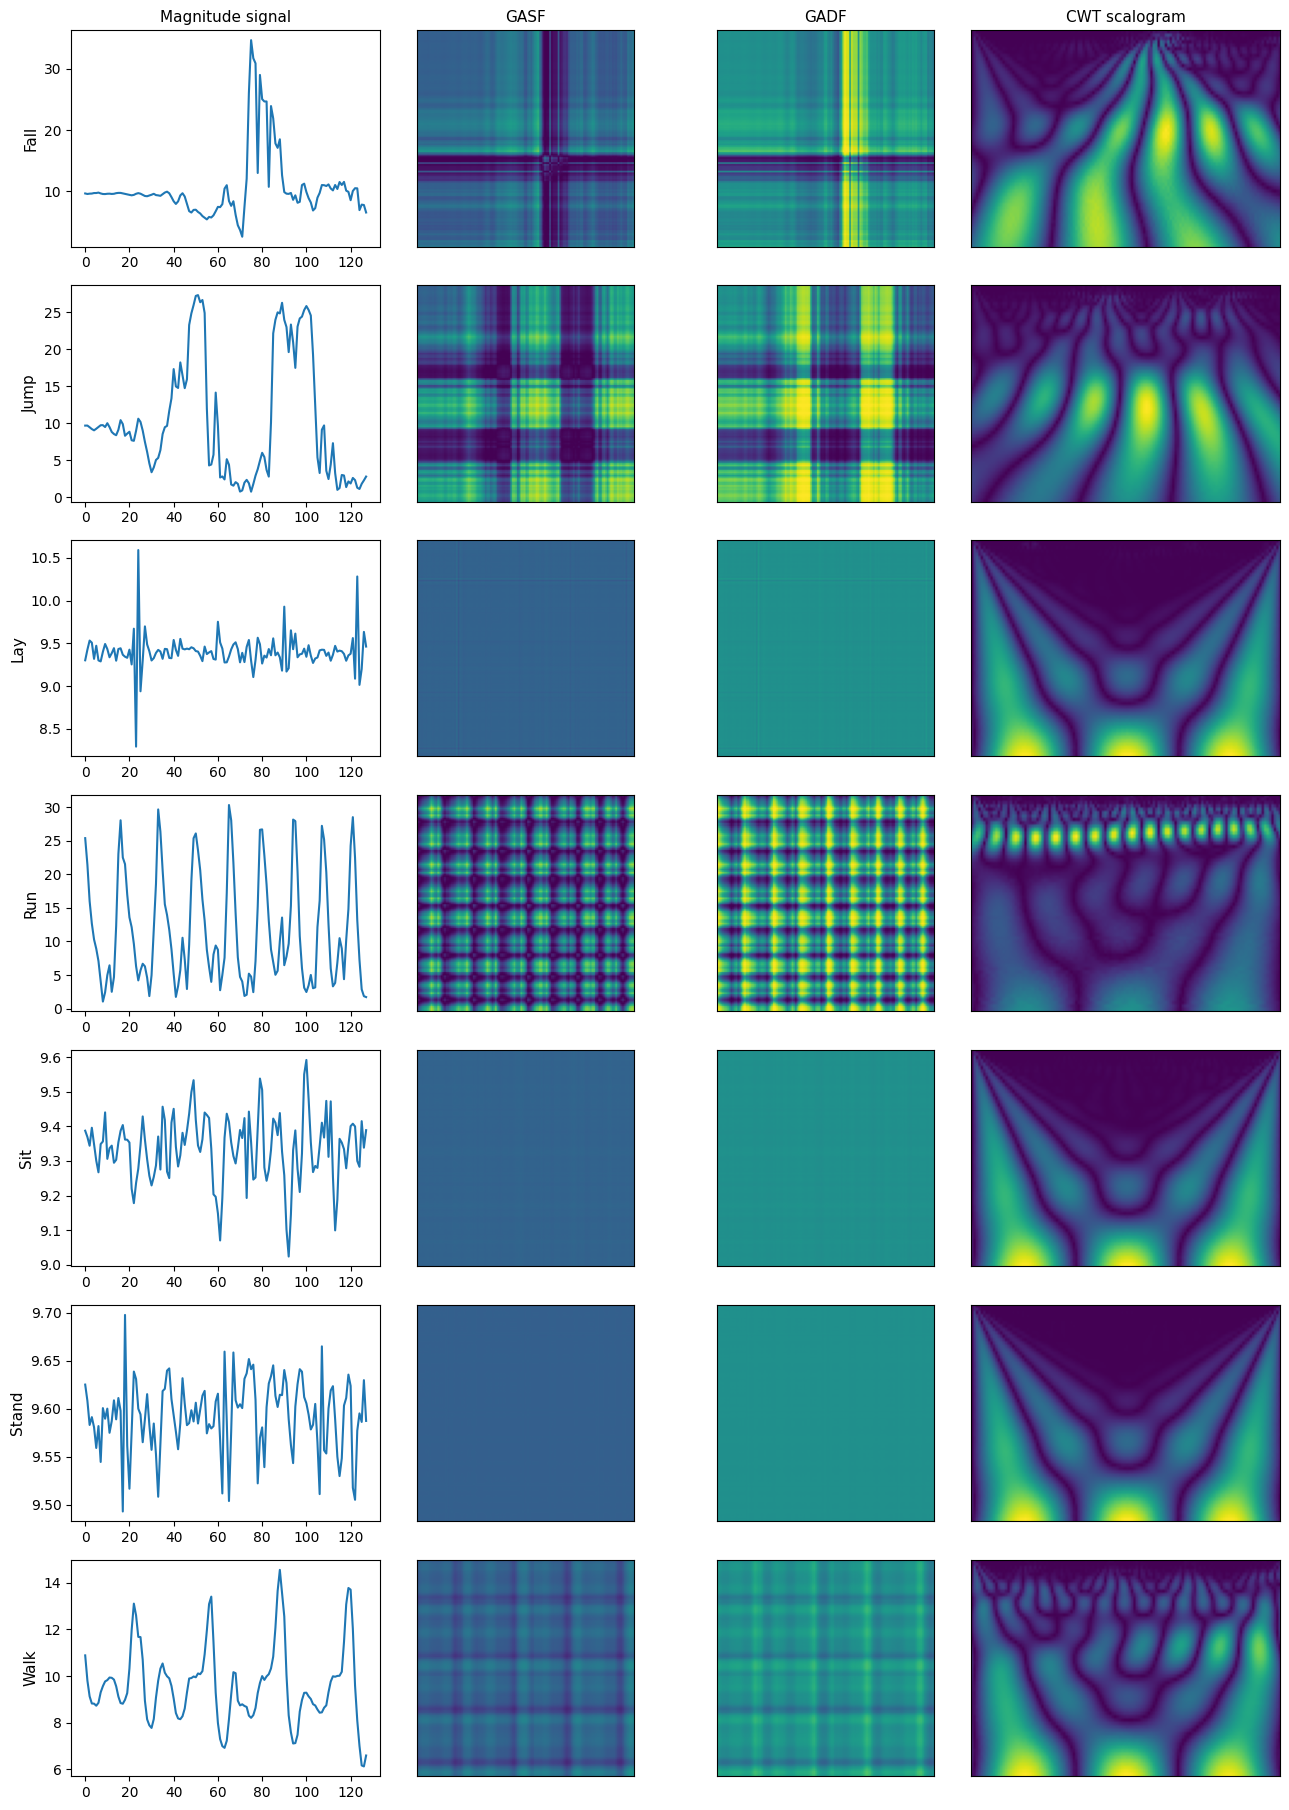

In [9]:
import numpy as np, matplotlib.pyplot as plt, pywt, os

def gasf(s):
    phi = np.arccos(np.clip(s, -1, 1));  return np.cos(phi[:, None] + phi[None, :])
def gadf(s):
    phi = np.arccos(np.clip(s, -1, 1));  return np.sin(phi[:, None] - phi[None, :])
def scalogram(s, n_scales=64):
    coefs, _ = pywt.cwt(s, np.arange(1, n_scales + 1), "morl");  return np.abs(coefs)

mag_all = np.sqrt((W ** 2).sum(2))              # magnitude of every window
MAG_MAX = mag_all.max()                         # ONE global scaling constant
rng = np.random.default_rng(0)

fig, axes = plt.subplots(len(classes), 4, figsize=(13, 2.6 * len(classes)))
for r, name in enumerate(classes):
    i = rng.choice(np.where(y == r)[0])         # one random window of this class
    m = mag_all[i];  s = 2 * m / MAG_MAX - 1
    axes[r, 0].plot(m);                       axes[r, 0].set_ylabel(name, fontsize=11)
    axes[r, 1].imshow(gasf(s), cmap="viridis", vmin=-1, vmax=1)
    axes[r, 2].imshow(gadf(s), cmap="viridis", vmin=-1, vmax=1)
    axes[r, 3].imshow(scalogram(m), aspect="auto", cmap="viridis")
    for c in range(1, 4):
        axes[r, c].set_xticks([]);  axes[r, c].set_yticks([])
for c, t in enumerate(["Magnitude signal", "GASF", "GADF", "CWT scalogram"]):
    axes[0, c].set_title(t, fontsize=11)
plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/task3_gaf_cwt_examples.png", dpi=150)
plt.show()

In [10]:
std_per_window = W.std(axis=1).mean(axis=1)      # average std over the 3 axes
for r, name in enumerate(classes):
    print(name, np.round(np.percentile(std_per_window[y == r], [10, 50, 90]), 2))

Fall [3.49 5.23 6.05]
Jump [4.57 6.07 7.66]
Lay [0.04 0.1  0.29]
Run [4.18 5.18 6.67]
Sit [0.04 0.09 0.21]
Stand [0.05 0.1  0.3 ]
Walk [1.22 1.5  2.03]


In [11]:
import glob, os, sys
import numpy as np, pandas as pd
sys.path.insert(0, ".")
from data_utils import load_uploaded_files, clean_raw_data     # YOUR loader and cleaner

def build_arrays(feat_df, data_dir="data"):
    """Windows of X,Y,Z AND of YOUR 'magnitude' column, in the order of features_128.csv."""
    raw, _ = load_uploaded_files(sorted(glob.glob(f"{data_dir}/*.mat")))
    cleaned, _ = clean_raw_data(raw)                  # this step creates cleaned["magnitude"]
    tables = {}
    for name, g in cleaned.assign(file=cleaned["source_file"].map(os.path.basename)
                                  ).groupby("file"):
        g = g.sort_values("sample_index")
        tables[name] = (g["sample_index"].to_numpy(),
                        g[["accel_x", "accel_y", "accel_z"]].to_numpy(float),
                        g["magnitude"].to_numpy(float))
    W = np.empty((len(feat_df), 128, 3))
    M = np.empty((len(feat_df), 128))
    for i, r in enumerate(feat_df.itertuples()):
        idx, xyz, mag = tables[os.path.basename(r.source_file)]
        lo = np.searchsorted(idx, r.window_start_sample)
        hi = np.searchsorted(idx, r.window_end_sample, side="right")
        assert hi - lo == 128, f"window {i}: found {hi - lo} samples"
        W[i], M[i] = xyz[lo:hi], mag[lo:hi]
    return W, M

feat = pd.read_csv("results/features_128.csv")
W, M = build_arrays(feat, "data")
print(W.shape, M.shape)
print("magnitude matches sqrt(x2+y2+z2):", np.allclose(M, np.sqrt((W ** 2).sum(2))))

(1920, 128, 3) (1920, 128)
magnitude matches sqrt(x2+y2+z2): True


In [12]:
MAG_MAX = M.max()          # fine for exploring; for the final runs, compute it on TRAIN windows only

def magnitude_to_image(m, kind):
    if kind == "gaf_rgb":                              # article: R = GASF, G = GADF, B = 0
        s = 2 * m / MAG_MAX - 1
        return np.stack([to_u8(gasf(s), -1, 1), to_u8(gadf(s), -1, 1),
                         np.zeros((128, 128), np.uint8)])
    c = cwt_scalogram(m)                               # CWT: grey image copied to 3 channels
    return np.stack([to_u8(c, 0, c.max())] * 3)

X_gaf = np.stack([magnitude_to_image(m, "gaf_rgb") for m in M])
X_cwt = np.stack([magnitude_to_image(m, "cwt") for m in M])
print(X_gaf.shape, X_cwt.shape)    # (1920, 3, 128, 128) (1920, 3, 64, 128)

NameError: name 'to_u8' is not defined

In [13]:
import numpy as np, pywt

def gasf(s):
    phi = np.arccos(np.clip(s, -1, 1));  return np.cos(phi[:, None] + phi[None, :])

def gadf(s):
    phi = np.arccos(np.clip(s, -1, 1));  return np.sin(phi[:, None] - phi[None, :])

def cwt_scalogram(sig, n_scales=64):
    coefs, _ = pywt.cwt(sig, np.arange(1, n_scales + 1), "morl");  return np.abs(coefs)

def to_u8(img, lo, hi):
    return (np.clip((img - lo) / (hi - lo + 1e-8), 0, 1) * 255).astype(np.uint8)

MAG_MAX = M.max()          # fine for exploring; for the final runs, compute it on TRAIN windows only

def magnitude_to_image(m, kind):
    if kind == "gaf_rgb":                              # article: R = GASF, G = GADF, B = 0
        s = 2 * m / MAG_MAX - 1
        return np.stack([to_u8(gasf(s), -1, 1), to_u8(gadf(s), -1, 1),
                         np.zeros((128, 128), np.uint8)])
    c = cwt_scalogram(m)                               # CWT: grey image copied to 3 channels
    return np.stack([to_u8(c, 0, c.max())] * 3)

X_gaf = np.stack([magnitude_to_image(m, "gaf_rgb") for m in M])
X_cwt = np.stack([magnitude_to_image(m, "cwt") for m in M])
print(X_gaf.shape, X_cwt.shape, X_gaf.dtype)

(1920, 3, 128, 128) (1920, 3, 64, 128) uint8


In [14]:
AX_MAX = np.abs(W).max()          # fine for exploring; TRAIN windows only for the final runs

def axes_to_gaf(w):               # w: (128, 3)  ->  R = GASF(X), G = GASF(Y), B = GASF(Z)
    return np.stack([to_u8(gasf(np.clip(w[:, a] / AX_MAX, -1, 1)), -1, 1) for a in range(3)])

X_rgb_gaf = np.stack([axes_to_gaf(w) for w in W])

def cwt_batch(S):                 # (N, 128) -> (N, 64, 128) floats
    return np.stack([cwt_scalogram(s) for s in S])

C_mag = cwt_batch(M)                                       # Method 1
CWT_MAX = np.percentile(C_mag, 99)                         # ONE scale for all windows
X_cwt = np.stack([np.stack([to_u8(c, 0, CWT_MAX)] * 3) for c in C_mag])

C_ax = np.stack([cwt_batch(W[:, :, a]) for a in range(3)], axis=1)   # Method 2: (N, 3, 64, 128)
X_rgb_cwt = to_u8(C_ax, 0, np.percentile(C_ax, 99))

for n, a in [("X_gaf", X_gaf), ("X_cwt", X_cwt), ("X_rgb_gaf", X_rgb_gaf), ("X_rgb_cwt", X_rgb_cwt)]:
    print(n, a.shape, a.dtype)

X_gaf (1920, 3, 128, 128) uint8
X_cwt (1920, 3, 64, 128) uint8
X_rgb_gaf (1920, 3, 128, 128) uint8
X_rgb_cwt (1920, 3, 64, 128) uint8


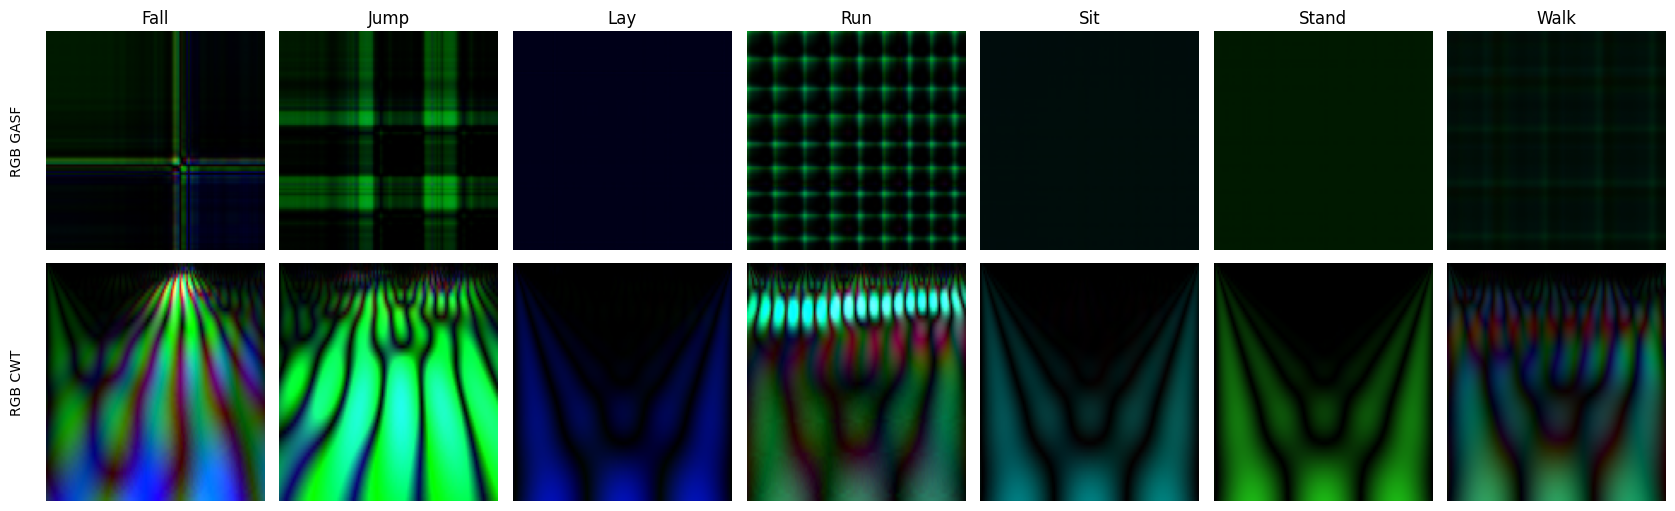

In [15]:
import matplotlib.pyplot as plt, os
rng = np.random.default_rng(0)
idx = [rng.choice(np.where(y == r)[0]) for r in range(len(classes))]
fig, axes = plt.subplots(2, len(classes), figsize=(2.4 * len(classes), 5.2))
for c, i in enumerate(idx):
    axes[0, c].imshow(X_rgb_gaf[i].transpose(1, 2, 0));  axes[0, c].set_title(classes[c])
    axes[1, c].imshow(X_rgb_cwt[i].transpose(1, 2, 0), aspect="auto")
    axes[0, c].axis("off");  axes[1, c].axis("off")
axes[0, 0].text(-0.1, 0.5, "RGB GASF", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right")
axes[1, 0].text(-0.1, 0.5, "RGB CWT", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right")
os.makedirs("figures", exist_ok=True)
plt.tight_layout();  plt.savefig("figures/task3_method2_examples.png", dpi=150);  plt.show()